# Q-Learning

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

ROOT = Path.home() / "Desktop/Project_lab"

files = sorted((ROOT / "results").glob("*_training.csv"))

assert len(files) == 3, f"{len(files)} fichiers détectés sur 3"

df = pd.concat(
    [pd.read_csv(f) for f in files],
    ignore_index=True
)

df = df.sort_values(["robot", "step"])

print("Dimensions :", df.shape)
print("Robots :", df["robot"].unique())

display(df.head())

Dimensions : (37855, 13)
Robots : <StringArray>
['robot_1', 'robot_2', 'robot_3']
Length: 3, dtype: str


,step,time,robot,episode,action,reward,episode_reward,min_distance,epsilon,loss,done,reason,buffer_size
0,10,0.64,robot_1,1,0,0.99,0.99,0.397063,1.0,NaN,False,NaN,1
1,15,0.96,robot_1,1,3,-0.21,0.78,0.398176,1.0,NaN,False,NaN,2
2,20,1.28,robot_1,1,4,-0.11,0.67,0.395980,1.0,NaN,False,NaN,3
3,25,1.60,robot_1,1,4,-0.11,0.56,0.381948,1.0,NaN,False,NaN,4
4,30,1.92,robot_1,1,2,0.19,0.75,0.397551,1.0,NaN,False,NaN,5


In [6]:
summary = df.groupby("robot").agg(
    transitions=("step", "count"),
    episodes=("episode", "nunique"),
    reward_mean=("reward", "mean"),
    reward_std=("reward", "std"),
    loss_mean=("loss", "mean"),
    epsilon_final=("epsilon", "last"),
    distance_mean=("min_distance", "mean")
)

display(summary.round(4))

,transitions,episodes,reward_mean,reward_std,loss_mean,epsilon_final,distance_mean
robot,,,,,,,
robot_1,12619,77,0.5078,0.9086,0.8586,0.05,0.4604
robot_2,12619,73,0.5294,0.7656,0.3755,0.05,0.4387
robot_3,12617,81,0.3623,1.0828,0.7036,0.05,0.5824


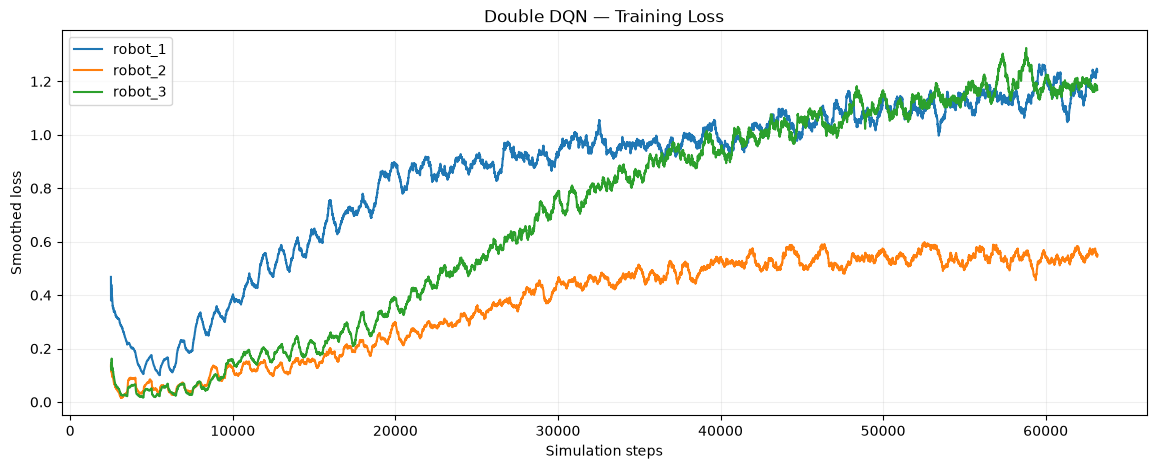

In [7]:
plt.figure(figsize=(14, 5))

for name, data in df.groupby("robot"):

    data = data.dropna(subset=["loss"])

    plt.plot(
        data["step"],
        data["loss"].rolling(100, min_periods=1).mean(),
        label=name
    )

plt.title("Double DQN — Training Loss")
plt.xlabel("Simulation steps")
plt.ylabel("Smoothed loss")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

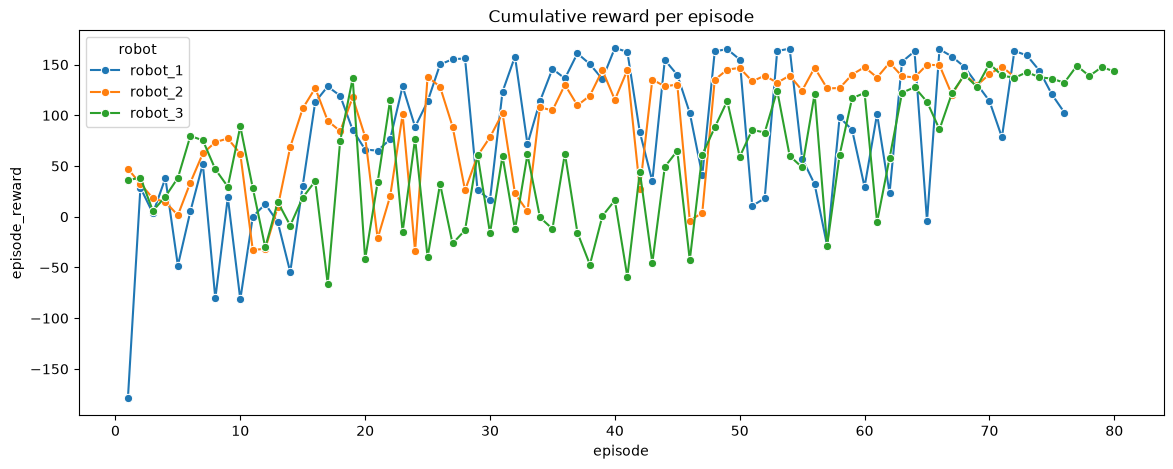

In [8]:
episodes = df[df["done"] == True].copy()

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=episodes,
    x="episode",
    y="episode_reward",
    hue="robot",
    marker="o"
)

plt.title("Cumulative reward per episode")
plt.show()

In [9]:
display(
    pd.crosstab(
        episodes["robot"],
        episodes["reason"]
    )
)

display(
    pd.crosstab(
        episodes["robot"],
        episodes["reason"],
        normalize="index"
    ).round(3) * 100
)

reason,stuck,timeout
robot,,
robot_1,9,67
robot_2,5,67
robot_3,13,67


reason,stuck,timeout
robot,,
robot_1,11.8,88.2
robot_2,6.9,93.1
robot_3,16.2,83.8
